# Egypt House Price Predictor

An end-to-end ML project that predicts property prices in Egypt from PropertyFinder listings (~20,000 listings).

**Pipeline:** load & clean data → explore → location and description features → model → honest evaluation → save the model for an app.

**Before running:** put `egypt_real_estate_listings.csv` (or the zip itself) next to this notebook, and change `DATA_PATH` below if your file has a different name.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA_PATH = "egypt_real_estate_listings.csv"   # or "archive.zip" (pandas can read a zip that contains a single CSV)
RANDOM_STATE = 42

## 1) Load the data

In [2]:
raw = pd.read_csv(DATA_PATH)
print(raw.shape)
raw.head()

(19924, 11)


,url,price,description,location,type,size,bedrooms,bathrooms,available_from,payment_method,down_payment
0,https://www.propertyfinder.eg/en/plp/buy/chale...,"8,000,000",OWN A CHALET IN EL GOUNA WITH A PRIME LOCATION...,"Swan Lake Gouna, Al Gouna, Hurghada, Red Sea",Chalet,732 sqft / 68 sqm,1+ Maid,1,31 Aug 2025,Cash,"1,200,000 EGP"
1,https://www.propertyfinder.eg/en/plp/buy/villa...,"25,000,000","For sale, a villa with immediate delivery in C...","Karmell, New Zayed City, Sheikh Zayed City, Giza",Villa,"2,368 sqft / 220 sqm",4,4,2 Sep 2025,Cash,"2,100,000 EGP"
2,https://www.propertyfinder.eg/en/plp/buy/chale...,"15,135,000","With a down payment of EGP 1,513,000, a fully ...","Azha North, Ras Al Hekma, North Coast",Chalet,"1,270 sqft / 118 sqm",2,2,19 Aug 2025,Cash,"1,513,000 EGP"
3,https://www.propertyfinder.eg/en/plp/buy/apart...,"12,652,000",Own an apartment in New Cairo with a minimal d...,"Taj City, 5th Settlement Compounds, The 5th Se...",Apartment,"1,787 sqft / 166 sqm",3,2,26 Aug 2025,Installments,"1,260,000 EGP"
4,https://www.propertyfinder.eg/en/plp/buy/villa...,"45,250,000",Project: Granville\nLocation: Fifth Settlement...,"Granville, New Capital City, Cairo",Villa,"4,306 sqft / 400 sqm",7,7,2 Sep 2025,Cash,"2,262,500 EGP"


In [3]:
# Every column is read as text. Missing values per column:
raw.isna().sum().to_frame("missing").assign(pct=lambda d: (d.missing / len(raw) * 100).round(1))

,missing,pct
url,0,0.0
price,539,2.7
description,78,0.4
location,91,0.5
type,77,0.4
size,77,0.4
bedrooms,144,0.7
bathrooms,140,0.7
available_from,663,3.3
payment_method,541,2.7


## 2) Cleaning and feature engineering

What we do:
- **Price and size:** convert to numbers (size is text like `732 sqft / 68 sqm`, so we take the sqm value).
- **Bedrooms:** separate the bedroom count from the maid's room flag (`3+ Maid`).
- **Location:** extract the **compound** (first part) and the **area** (second to last part).
- **Drop `down_payment`:** missing in ~73% of rows and directly tied to the price.
- **Drop `available_from`:** these are just listing dates (Aug/Sep 2025), carrying no information.

In [4]:
df = raw.copy()

df["price"] = pd.to_numeric(df["price"].str.replace(",", "", regex=False), errors="coerce")
df["size_sqm"] = pd.to_numeric(
    df["size"].str.extract(r"/\s*([\d,]+)\s*sqm")[0].str.replace(",", ""), errors="coerce")

bed = df["bedrooms"].astype(str)
df["has_maid"] = bed.str.contains("Maid").astype(int)
df["beds"] = bed.str.extract(r"(\d+)")[0].astype(float)
df.loc[bed.str.lower() == "studio", "beds"] = 0
df["baths"] = df["bathrooms"].astype(str).str.extract(r"(\d+)")[0].astype(float)

parts = df["location"].fillna("").str.split(r"\s*,\s*", regex=True)
df["compound"] = parts.str[0]
df["area"] = parts.str[-2].where(parts.str.len() > 1, parts.str[-1])

df["installments"] = (df["payment_method"] == "Installments").astype(int)

# Remove duplicate listings and rows missing the essentials
before = len(df)
df = df.drop_duplicates(subset=["price", "description", "location"])
df = df.dropna(subset=["price", "size_sqm", "type", "area"])

# Outliers: drop the top 1% of prices and unrealistic sizes
df = df[(df["price"] < df["price"].quantile(0.99)) & (df["size_sqm"].between(20, 2000))].reset_index(drop=True)
print(f"{before:,} -> {len(df):,} rows after cleaning")

19,924 -> 18,845 rows after cleaning


### Features from the listing description

In [5]:
desc = df["description"].fillna("").str.lower()
KEYWORDS = {
    "fully_finished": r"fully[\s-]*finished",
    "semi_finished":  r"semi[\s-]*finished",
    "core_shell":     r"core\s*(?:&|and)\s*shell",
    "sea_view":       r"sea\s*view|beach|lagoon|marina",
    "garden":         r"garden",
    "roof":           r"roof",
    "ready":          r"ready to move|immediate|ready for delivery",
    "furnished":      r"furnished",
    "pool":           r"pool",
    "view":           r"view",
    "years_plan":     r"\d+\s*years",
    "kitchen_acs":    r"kitchen|air condition|\bacs?\b",
    "golf":           r"golf",
    "private":        r"private",
}
for name, pattern in KEYWORDS.items():
    df[name] = desc.str.contains(pattern, regex=True).astype(int)
df["desc_len"] = np.log1p(df["description"].fillna("").str.len())

TEXT_FEATS = list(KEYWORDS) + ["desc_len"]
df[TEXT_FEATS].mean().round(3).sort_values(ascending=False).to_frame("share_of_listings").T

,desc_len,view,fully_finished,kitchen_acs,sea_view,garden,years_plan,pool,ready,private,roof,semi_finished,furnished,golf,core_shell
share_of_listings,6.689,0.522,0.359,0.321,0.3,0.289,0.27,0.263,0.239,0.196,0.107,0.082,0.081,0.064,0.047


## 3) Exploratory analysis

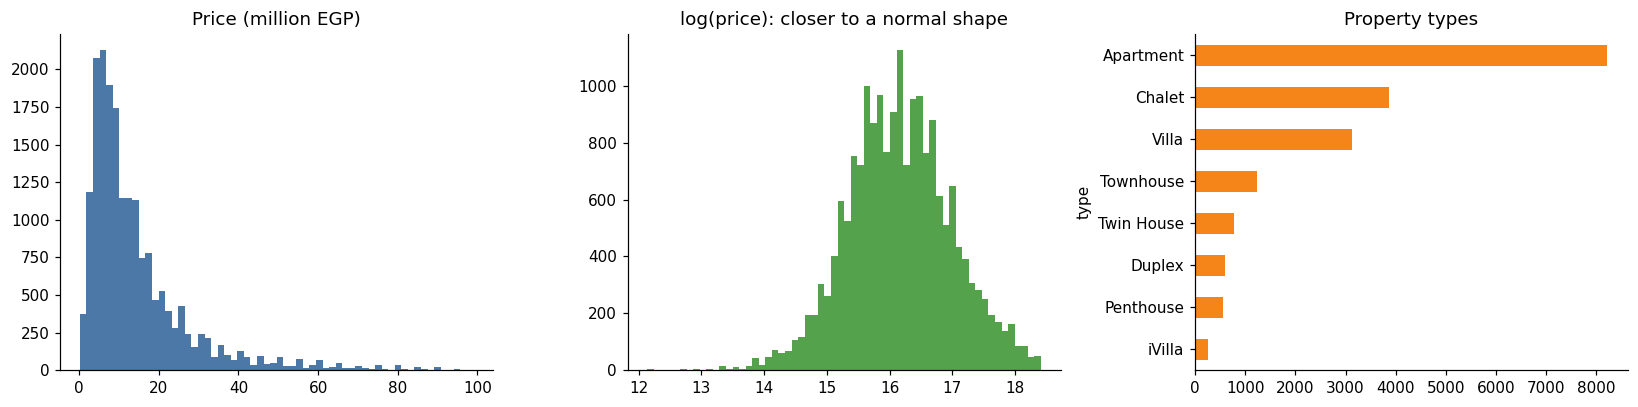

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(df["price"] / 1e6, bins=60, color="#4C78A8"); ax[0].set_title("Price (million EGP)")
ax[1].hist(np.log1p(df["price"]), bins=60, color="#54A24B"); ax[1].set_title("log(price): closer to a normal shape")
df["type"].value_counts().head(8).plot.barh(ax=ax[2], color="#F58518"); ax[2].invert_yaxis(); ax[2].set_title("Property types")
plt.tight_layout(); plt.show()

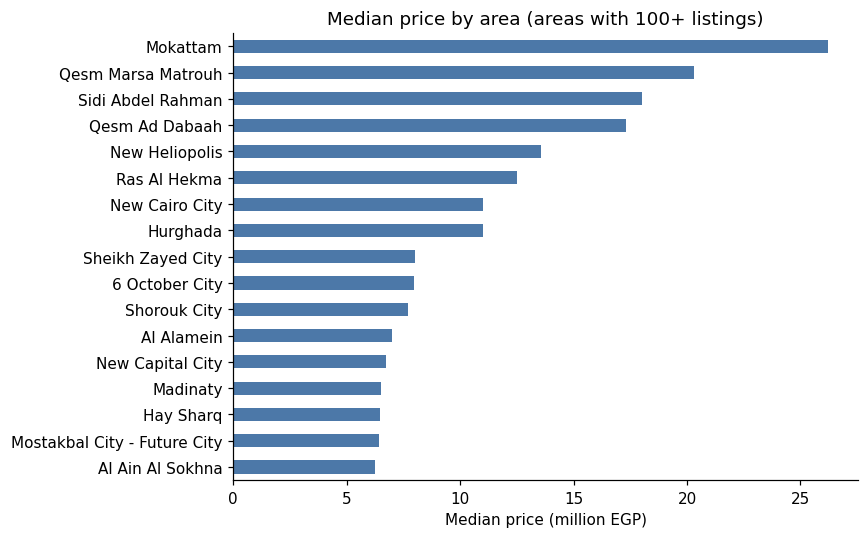

In [7]:
top = df.groupby("area")["price"].agg(["median", "count"]).query("count >= 100").sort_values("median")
fig, ax = plt.subplots(figsize=(8, 5))
(top["median"] / 1e6).plot.barh(ax=ax, color="#4C78A8")
ax.set_xlabel("Median price (million EGP)"); ax.set_ylabel("")
ax.set_title("Median price by area (areas with 100+ listings)")
plt.tight_layout(); plt.show()

## 4) Train/test split and target encoding

- **Target = `log(price)`**, because prices are heavily right-skewed.
- **Split before any encoding** to avoid data leakage.
- **Target encoding** for compound (~1,450 values) and area: replace each value with the smoothed mean of `log(price)` for that value, computed on the training set only and out-of-fold, so a row never sees its own price.

In [8]:
df["y"] = np.log1p(df["price"])
df["log_size"] = np.log(df["size_sqm"])

train, test = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
train, test = train.copy(), test.copy()

def make_encoder(frame, col, smooth=10):
    """Smoothed mean of the target per category (rare categories shrink toward the global mean)."""
    g = frame["y"].mean()
    st = frame.groupby(col)["y"].agg(["mean", "count"])
    enc = (st["mean"] * st["count"] + g * smooth) / (st["count"] + smooth)
    return enc, g

def target_encode(col, train, test, k=5, smooth=10):
    """Out-of-fold encoding for train, full-train encoding for test."""
    oof = pd.Series(index=train.index, dtype=float)
    for a, b in KFold(k, shuffle=True, random_state=0).split(train):
        enc, g = make_encoder(train.iloc[a], col, smooth)
        oof.iloc[b] = train.iloc[b][col].map(enc).fillna(g).values
    enc, g = make_encoder(train, col, smooth)
    return oof, test[col].map(enc).fillna(g)

for c in ["compound", "area"]:
    train[c + "_te"], test[c + "_te"] = target_encode(c, train, test)

BASE_FEATS = ["log_size", "size_sqm", "beds", "baths", "has_maid", "installments", "compound_te", "area_te"]
NUM_FEATS = BASE_FEATS + TEXT_FEATS

def build_X(frame, num_cols, type_cols=None):
    X = pd.concat([frame[num_cols], pd.get_dummies(frame["type"])], axis=1)
    if type_cols is not None:
        X = X.reindex(columns=type_cols, fill_value=0)
    return X

X_tr = build_X(train, NUM_FEATS)
X_te = build_X(test, NUM_FEATS, X_tr.columns)
medians = X_tr.median()
X_tr, X_te = X_tr.fillna(medians), X_te.fillna(medians)
X_tr.shape, X_te.shape

((15076, 39), (3769, 39))

## 5) Models and evaluation

We compare **four setups** on the same test set:
1. **Baseline:** always predict the median price (any real model must beat this).
2. **Ridge:** a simple linear model.
3. **Random Forest without description features.**
4. **Random Forest with all features.**

Metrics are in EGP after converting back from log. **MAPE** (relative error) is easier to interpret than MAE, because very expensive listings inflate the MAE.

In [9]:
def evaluate(name, pred_log):
    p, t = np.expm1(pred_log), np.expm1(test["y"])
    return {"model": name,
            "MAE": mean_absolute_error(t, p),
            "MedAE": median_absolute_error(t, p),
            "MAPE %": np.mean(np.abs(p - t) / t) * 100,
            "R2 (log)": r2_score(test["y"], pred_log)}

results = []
results.append(evaluate("Baseline (median)", np.full(len(test), train["y"].median())))

mu, sd = X_tr.mean(), X_tr.std().replace(0, 1)
ridge = Ridge(alpha=1.0).fit((X_tr - mu) / sd, train["y"])
results.append(evaluate("Ridge", ridge.predict((X_te - mu) / sd)))

Xb_tr = build_X(train, BASE_FEATS)
Xb_te = build_X(test, BASE_FEATS, Xb_tr.columns)
mb = Xb_tr.median()
rf_base = RandomForestRegressor(300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
rf_base.fit(Xb_tr.fillna(mb), train["y"])
results.append(evaluate("Random Forest (no text features)", rf_base.predict(Xb_te.fillna(mb))))

rf = RandomForestRegressor(300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE).fit(X_tr, train["y"])
rf_pred = rf.predict(X_te)
results.append(evaluate("Random Forest (all features)", rf_pred))

results_df = pd.DataFrame(results).set_index("model")
print(results_df.round(3).to_string(formatters={"MAE": "{:,.0f}".format, "MedAE": "{:,.0f}".format}))

                                       MAE     MedAE  MAPE %  R2 (log)
model                                                                 
Baseline (median)                8,938,995 5,223,000  85.199    -0.001
Ridge                            4,716,405 2,562,297  42.347     0.681
Random Forest (no text features) 4,153,744 2,219,764  37.409     0.721
Random Forest (all features)     3,943,464 2,017,126  34.947     0.749


### Actual vs predicted, and the most important features

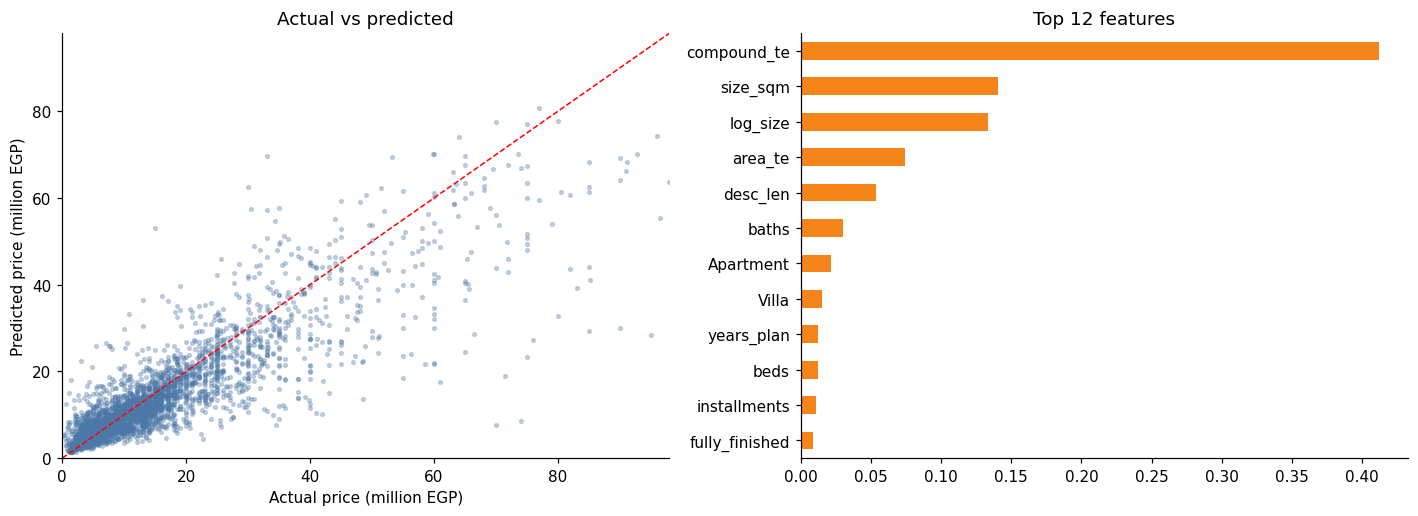

In [10]:
true = np.expm1(test["y"]); pred = np.expm1(rf_pred)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(true / 1e6, pred / 1e6, s=6, alpha=0.3, color="#4C78A8")
lim = [0, max(true.max(), pred.max()) / 1e6]
ax[0].plot(lim, lim, "r--", lw=1); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("Actual price (million EGP)"); ax[0].set_ylabel("Predicted price (million EGP)")
ax[0].set_title("Actual vs predicted")

imp = pd.Series(rf.feature_importances_, index=X_tr.columns).sort_values().tail(12)
imp.plot.barh(ax=ax[1], color="#F58518"); ax[1].set_title("Top 12 features")
plt.tight_layout(); plt.show()

### Error analysis: where does the model go wrong?

In [11]:
err = pd.DataFrame({"type": test["type"].values, "area": test["area"].values,
                    "true": true.values, "pred": pred})
err["ape"] = (err["pred"] - err["true"]).abs() / err["true"]

print("Median relative error by property type:")
display(err.groupby("type")["ape"].agg(["median", "count"]).query("count >= 30").sort_values("median").round(3))

print("Five worst predictions:")
display(err.sort_values("ape", ascending=False).head(5).round(2))

Median relative error by property type:


,median,count
type,,
iVilla,0.138,48
Penthouse,0.157,121
Twin House,0.182,168
Chalet,0.187,770
Duplex,0.190,115
Apartment,0.196,1610
Townhouse,0.218,254
Villa,0.226,636


Five worst predictions:


,type,area,true,pred,ape
1244,Apartment,6 October City,202500.0,5236543.22,24.86
2992,Apartment,6 October City,233766.0,5423580.63,22.20
2603,Chalet,Sidi Abdel Rahman,650000.0,12483348.75,18.21
781,Townhouse,Sheikh Zayed City,1150000.0,15115694.80,12.14
2716,Townhouse,New Cairo City,1375000.0,17974326.06,12.07


## 6) Prediction intervals

A Random Forest lets us return a **range** instead of a single number: ask each tree separately, then take the 25th and 75th percentiles.
We also check that this range really covers the true price about 50% of the time.

In [12]:
def predict_range(model, X, lo=25, hi=75):
    tree_preds = np.column_stack([t.predict(X.values) for t in model.estimators_])
    return (np.expm1(np.percentile(tree_preds, lo, axis=1)),
            np.expm1(np.median(tree_preds, axis=1)),
            np.expm1(np.percentile(tree_preds, hi, axis=1)))

low, mid, high = predict_range(rf, X_te)
coverage = np.mean((true.values >= low) & (true.values <= high))
print(f"The 25%-75% range covered {coverage:.0%} of true prices (should be ~50%)")

The 25%-75% range covered 53% of true prices (should be ~50%)


## 7) Save the model for the app

We recompute the encodings on **all** the data and retrain, then save everything the app needs in a single file.
(The evaluation above used the train/test split; this final version is the one for deployment.)

In [13]:
final = df.copy()
enc_compound, g_compound = make_encoder(final, "compound")
enc_area, g_area = make_encoder(final, "area")

# Out-of-fold encoding on the full data so the final model never sees a row's own price in its encoding
final["compound_te"], _ = target_encode("compound", final, final.iloc[:1])
final["area_te"], _ = target_encode("area", final, final.iloc[:1])

X_all = build_X(final, NUM_FEATS)
medians_all = X_all.median()
X_all = X_all.fillna(medians_all)

final_model = RandomForestRegressor(300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
final_model.fit(X_all, final["y"])

bundle = {
    "model": final_model, "columns": list(X_all.columns), "medians": medians_all,
    "enc_compound": enc_compound, "g_compound": g_compound,
    "enc_area": enc_area, "g_area": g_area,
    "keywords": KEYWORDS, "text_feats": TEXT_FEATS, "num_feats": NUM_FEATS,
    "types": sorted(final["type"].unique()),
    "areas": sorted(final["area"].unique()),
    "compounds_by_area": final.groupby("area")["compound"].apply(lambda s: sorted(s.unique())).to_dict(),
}
joblib.dump(bundle, "price_model.joblib", compress=3)
print("Saved: price_model.joblib")

Saved: price_model.joblib


## 8) Prediction function (the same one the app will use)

In [14]:
def predict_price(type_, area, compound, size_sqm, beds, baths,
                  has_maid=0, installments=0, description=""):
    b = joblib.load("price_model.joblib")
    d = description.lower()
    row = {
        "log_size": np.log(size_sqm), "size_sqm": size_sqm, "beds": beds, "baths": baths,
        "has_maid": has_maid, "installments": installments,
        "compound_te": b["enc_compound"].get(compound, b["g_compound"]),
        "area_te": b["enc_area"].get(area, b["g_area"]),
        "desc_len": np.log1p(len(description)),
    }
    for k, pat in b["keywords"].items():
        row[k] = int(bool(re.search(pat, d)))
    X = pd.DataFrame([row])[b["num_feats"]]
    X = pd.concat([X, pd.get_dummies(pd.Series([type_]))], axis=1)
    X = X.reindex(columns=b["columns"], fill_value=0).fillna(b["medians"])
    low, mid, high = predict_range(b["model"], X)
    return {"low": float(low[0]), "estimate": float(mid[0]), "high": float(high[0])}

example = predict_price("Apartment", "New Cairo City", "Mivida", size_sqm=150, beds=3, baths=2,
                        installments=1, description="Fully finished apartment with garden view, 8 years installments")
{k: f"{v:,.0f} EGP" for k, v in example.items()}

{'low': '6,974,960 EGP',
 'estimate': '14,544,685 EGP',
 'high': '17,289,029 EGP'}

## Summary and notes (for the README)

- The model beats the baseline by a wide margin (relative error drops from ~85% to ~35%).
- **The compound is by far the most important feature**: the exact location drives price more than size or bedroom count.
- Description features give a small but real improvement.
- **Limitations:** the data are *asking* prices, not actual sale prices, and it lacks finishing details, floor and view, so the output is an estimate, not an official valuation.
- **The worst predictions involve implausible prices** (for example, an apartment listed at 202k EGP). The listed price is probably an installment or down payment rather than the full price. That is a data problem rather than a model problem, and stricter cleaning (such as a minimum price per sqm) could improve the results.
- `desc_len` may just be a proxy for the type of advertiser (large developers write long descriptions) rather than a direct cause of price.
- Next step: a Gradio app deployed to Hugging Face Spaces.